In [2]:
import sys
import os
sys.path.insert(0, r"D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda")  # ưu tiên folder custom
import pandas as pd
import pickle
from sdv.single_table import MAECTGANSynthesizer
import numpy as np
import csv
import torch
# In kết quả
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix,matthews_corrcoef
from sklearn.metrics import average_precision_score
from utils import plot_normal_vs_abnormal_tsne, plot_normal_vs_abnormal_pca
import pandas as pd
import sdv
print(sdv.__file__)

import ctgan
print(ctgan.__file__)

def load_threshold(path):
    with open(path, "rb") as f:
        return pickle.load(f)
    

    

D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda\sdv\__init__.py
D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda\ctgan\__init__.py


In [3]:
percentage = 1.0
dataset = "unsw"
epochs = 200
best_epoch = 20
margin = 5.0
lamda = 0.1
type_mode="all_seed_42"



path_model=f"results/all_seed_42/percentage_{percentage}/mae_{dataset}_{epochs}_margin_{margin}_lambda_{lamda}/checkpoints"
path_data=f"results/all_seed_42/percentage_{percentage}/mae_{dataset}_{epochs}_margin_{margin}_lambda_{lamda}"
path_save=f"results/all_seed_42/percentage_{percentage}/mae_{dataset}_{epochs}_margin_{margin}_lambda_{lamda}/per_attack_results"
if not os.path.exists(path_save):
    os.makedirs(path_save)


X_test = pd.read_csv(f"{path_data}/{dataset}_X_test.csv")
y_test = pd.read_csv(f"{path_data}/{dataset}_y_test.csv")['label']
X_val_normal= pd.read_csv(f"{path_data}/{dataset}_X_val_normal.csv")
y_val_normal= pd.read_csv(f"{path_data}/{dataset}_y_val_normal.csv")['label']

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)
print("X_val_normal shape:", X_val_normal.shape)
print("y_val_normal shape:", y_val_normal.shape)

model_file = f"{path_model}/MAE_{dataset}_epoch_{best_epoch}.pkl"
if not os.path.exists(model_file):
    print(f"Model file for epoch {best_epoch} does not exist: {model_file}")

synthesizer = MAECTGANSynthesizer.load(f'{path_model}/MAE_{dataset}_epoch_{best_epoch}.pkl')

avg_loss,threshold_re, threshold_z_0, threshold_95,threshold_99 = synthesizer.get_threshold_mae(X_val_normal)


print("Threshold_re:", threshold_re)
print("Threshold_z:", threshold_z_0)
print("Threshold_95:", threshold_95)
print("Threshold_99:", threshold_99)

X_test shape: (82332, 40)
y_test shape: (82332,)
X_val_normal shape: (11200, 40)
y_val_normal shape: (11200,)


c:\Users\Admin\anaconda3\envs\ctgan_env\lib\site-packages\sklearn\base.py:442: InconsistentVersionWarning: Trying to unpickle estimator BayesianGaussianMixture from version 1.8.0 when using version 1.7.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
D:\CTGAN_SUAMODEL\SDV_D1_D2_detect_lamda\sdv\_utils.py:284: SDV Version Warning: You are currently on SDV version 1.32.0 but this synthesizer was created on version None. The latest bug fixes and features may not be available for this synthesizer. To see these enhancements, create and train a new synthesizer on this version.
  warnings.warn(message, SDVVersionWarning)


Threshold_re: (np.float32(0.020699926), np.float32(0.009273271))
Threshold_z: (np.float32(0.25146553), np.float32(0.34341004))
Threshold_95: 0.48940927
Threshold_99: 1.2303505


In [4]:

import numpy as np
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

def evaluate_ids_metrics(
    y_true,
    scores,
    far_levels=(0.01, 0.10)
):
    """
    Compute IDS metrics:
    - AUC (%)
    - PR-AUC (%)
    - TPR@FAR = 1%, 10%

    Parameters
    ----------
    y_true : array-like
        Ground truth labels (0: normal, 1: attack)
    scores : array-like
        Anomaly scores (higher = more abnormal)
    far_levels : tuple
        FAR levels, e.g. (0.01, 0.10)

    Returns
    -------
    results : dict
        {
          "AUC": float,
          "PR-AUC": float,
          "TPR@FAR=1%": float,
          "TPR@FAR=10%": float
        }
    """

    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores)

    results = {}

    # =========================
    # 1. AUC (%)
    # =========================
    if len(np.unique(y_true)) < 2:
        results["AUC"] = 0.0
    else:
        results["AUC"] = roc_auc_score(y_true, scores) * 100

    # =========================
    # 2. PR-AUC (%)
    # =========================
    results["PR-AUC"] = average_precision_score(y_true, scores) * 100

    # =========================
    # 3. TPR@FAR
    # =========================
    scores_normal = scores[y_true == 0]

    for far in far_levels:
        # threshold theo percentile của normal
        threshold = np.percentile(scores_normal, 100 * (1 - far))

        y_pred = (scores >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
        tpr = tp / (tp + fn + 1e-12)

        results[f"TPR@FAR={int(far*100)}%"] = tpr * 100

    return results



def predict_and_evaluate(
    Z_norm_test,
    y_true,
    threshold,
    save_dir="results", 
    filename="test_results.csv",
    device="cuda" if torch.cuda.is_available() else "cpu",
    batch_size=128,
    k_std=3.0,
    mode="std" #"re" #"dist"    
):
    """
    AE-based anomaly detection evaluation
    - Predict anomaly using reconstruction error
    - Compute AUC, ACC, F1, Precision, Recall
    - Compute confusion matrix
    - Save everything to TXT
    """
    # -------------------------
    # Prediction
    # -------------------------
    os.makedirs(save_dir, exist_ok=True)
    save_path = os.path.join(save_dir, filename)
    print(f"Latent errors shape: {Z_norm_test.shape}")
    #y_true = np.concatenate(y_true)
    
    if mode=="re":
        mu, std = threshold
        threshold_test = mu + k_std * std
    elif mode=="std":
        mu, std = threshold
        threshold_test = mu + k_std * std
    elif mode=="dist":
        threshold_test = threshold
    
    y_pred = (Z_norm_test > threshold_test).astype(int)
    print("y_pred_shape:", y_pred.shape )
    
    print("Predicted label distribution in test set:")
    labels, counts = np.unique(y_pred, return_counts=True)
    for label, count in zip(labels, counts):
        print(f"Label {label}: {count} samples")
    
    
    
    y_true = (y_true != 0).astype(int)  # 0 = normal
    print("True label distribution in test set:")
    
    labels, counts = np.unique(y_true, return_counts=True)
    for label, count in zip(labels, counts):
        print(f"Label {label}: {count} samples")

    # =========================
    # 3. METRICS
    # =========================
    unique_classes = np.unique(y_true)

    # AUC-ROC
    if len(unique_classes) < 2:
        auc = 0.0
    else:
        auc = roc_auc_score(y_true, Z_norm_test)

    # PR-AUC (Average Precision)
    if len(unique_classes) < 2:
        pr_auc = 0.0
    else:
        pr_auc = average_precision_score(y_true, Z_norm_test)

    # Threshold-based metrics (fixed threshold => y_pred đã có)
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)

    cm = confusion_matrix(y_true, y_pred)  # [[TN, FP],[FN, TP]]
    tn, fp, fn, tp = cm.ravel()

    # FAR = FP/(FP+TN)
    far = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    # MDR = FN/(FN+TP)
    mdr = fn / (fn + tp) if (fn + tp) > 0 else 0.0

    # MCC (fixed threshold)
    mcc = matthews_corrcoef(y_true, y_pred) if len(unique_classes) == 2 else 0.0
    
    results_df = pd.DataFrame({
    "Metric": [
        "Threshold",
        "AUC (ROC)",
        "PR-AUC",
        "FAR (FPR @ fixed thres)",
        "MDR (FNR @ fixed thres)",
        "ACC",
        "F1",
        "Precision",
        "Recall (TPR)",
        "MCC (fixed thres)"
    ],
    "Value": [
        threshold_test,
        auc,
        pr_auc,
        far,
        mdr,
        acc,
        f1,
        precision,
        recall,
        mcc
    ]
    })
    return results_df


In [5]:
#classify_test_data
print("Classify test data using MAE 95% error...")
test_re_loss, test_z_norm, test_y_true = synthesizer.get_score_mae(X_test, y_test)
results_df=predict_and_evaluate(
    Z_norm_test=test_z_norm,
    y_true=test_y_true,
    threshold=threshold_95,
    save_dir=path_data,
    filename=f"test_results_mae_95_epoch_{best_epoch}.csv",
    mode="dist"
)
results_df

Classify test data using MAE 95% error...
[Time] get_score_mae: 667.46 ms
Latent errors shape: (82332,)
y_pred_shape: (82332,)
Predicted label distribution in test set:
Label 0: 47101 samples
Label 1: 35231 samples
True label distribution in test set:
Label 0: 37000 samples
Label 1: 45332 samples


,Metric,Value
0,Threshold,0.489409
1,AUC (ROC),0.876044
2,PR-AUC,0.904802
3,FAR (FPR @ fixed thres),0.076432
4,MDR (FNR @ fixed thres),0.285207
5,ACC,0.808616
6,F1,0.804414
7,Precision,0.919730
8,Recall (TPR),0.714793
9,MCC (fixed thres),0.641788


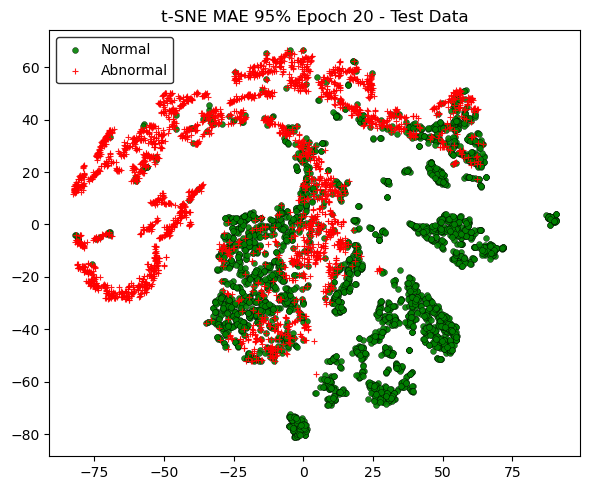

In [6]:
#tnse TEST DATA
z= synthesizer.get_latent_z_mae(X_test)
plot_normal_vs_abnormal_tsne(
    z[test_y_true==0],
    z[test_y_true!=0],
    title=f"t-SNE MAE 95% Epoch {best_epoch} - Test Data",
    save_path=f"{path_data}/tsne_Z_epoch_{best_epoch}_test.png",
    perplexity=30,
    learning_rate="auto",
    n_iter=1000, 
    random_state=42,
)




##1. Xử lý với Bot attack

In [7]:
def load_data_unsw_perattack():
    import pandas as pd
    import numpy as np
    
    path_train = "./data/unsw/UNSW_NB15_training-set.csv"
    path_test = "./data/unsw/UNSW_NB15_testing-set.csv"

    train_data = pd.read_csv(path_train)
    test_data = pd.read_csv(path_test)

    full_data = pd.concat([train_data, test_data], ignore_index=True)

    # Clean
    full_data.replace([np.inf, -np.inf], np.nan, inplace=True)
    full_data.dropna(inplace=True)

    test_data.replace([np.inf, -np.inf], np.nan, inplace=True)
    test_data.dropna(inplace=True)

    df_full = full_data.copy()
    df_test = test_data.copy()

    # Lấy cột attack trước khi drop
    attack_full = df_full["attack_cat"]
    attack_test = df_test["attack_cat"]

    # Nhãn nhị phân (nếu vẫn cần)
    y_full = (df_full['label'] != 0).astype(int)

    # Drop cột
    drop_cols = ["id", "attack_cat", "label"]
    for col in drop_cols:
        df_full = df_full.drop(col, axis=1)
        df_test = df_test.drop(col, axis=1)

    # =========================
    # Lấy mẫu theo từng attack
    # =========================
    attack_labels = sorted(attack_test.unique())

    samples_by_attack = {}

    for attack in attack_labels:
        samples_by_attack[attack] = df_test[attack_test == attack]

    return df_full, y_full, samples_by_attack, attack_labels

In [8]:
_,_,test_samples_by_label, test_labels=load_data_unsw_perattack()
print (test_labels)

rows = []
x_test_normal=None
y_test_normal=None
for attack_index in test_labels:
    if attack_index =="Normal":
        x_test_normal=test_samples_by_label[attack_index]
        y_test_normal=np.zeros(len(x_test_normal),dtype=int)

for attack_index in test_labels:
    print(f"\n\n===========================Processing attack: {attack_index}===========================")
    if attack_index =="Normal":
        continue
    
    X_attack= test_samples_by_label[attack_index]
    y_attack = np.ones(len(X_attack), dtype=int)  # all abnormal = 1

    X_combined = pd.concat([x_test_normal, X_attack], ignore_index=True)
    y_combined = np.concatenate([y_test_normal, y_attack])

    #classify_test_data
    print(f"Classify test attack: {attack_index} using MAE 95% error...")
    test_re_loss, test_z_norm, test_y_true = synthesizer.get_score_mae(X_combined, y_combined)
    metrics = evaluate_ids_metrics(y_combined, test_z_norm)
    row = {
        "Dataset": "UNSW",
        "Attack": attack_index,
        "Model": "SSAE",
        "samples":X_attack.shape[0],
        **metrics
    }
    rows.append(row)
df = pd.DataFrame(rows)
display(df)
df.to_csv(f"{path_save}/results_unsw_per_attack.csv", index=False)
    



['Analysis', 'Backdoor', 'DoS', 'Exploits', 'Fuzzers', 'Generic', 'Normal', 'Reconnaissance', 'Shellcode', 'Worms']


===========================Processing attack: Analysis===========================
Classify test attack: Analysis using MAE 95% error...
[Time] get_score_mae: 339.47 ms


===========================Processing attack: Backdoor===========================
Classify test attack: Backdoor using MAE 95% error...
[Time] get_score_mae: 320.81 ms


===========================Processing attack: DoS===========================
Classify test attack: DoS using MAE 95% error...
[Time] get_score_mae: 412.55 ms


===========================Processing attack: Exploits===========================
Classify test attack: Exploits using MAE 95% error...
[Time] get_score_mae: 473.46 ms


===========================Processing attack: Fuzzers===========================
Classify test attack: Fuzzers using MAE 95% error...
[Time] get_score_mae: 390.51 ms


===========================Processing attack

,Dataset,Attack,Model,samples,AUC,PR-AUC,TPR@FAR=1%,TPR@FAR=10%
0,UNSW,Analysis,SSAE,677,97.799425,55.704111,90.546529,94.682422
1,UNSW,Backdoor,SSAE,583,97.715247,52.135698,90.909091,95.883362
2,UNSW,DoS,SSAE,4089,94.758941,78.799418,74.223527,88.041086
3,UNSW,Exploits,SSAE,11132,89.353369,75.758589,34.953288,74.020841
4,UNSW,Fuzzers,SSAE,6062,68.005032,37.938516,21.791488,37.578357
5,UNSW,Generic,SSAE,18871,95.966899,89.801165,34.926607,93.630438
6,UNSW,Reconnaissance,SSAE,3496,63.128424,19.025759,10.211670,27.316934
7,UNSW,Shellcode,SSAE,378,61.436068,1.593367,0.000000,21.957672
8,UNSW,Worms,SSAE,44,73.136916,0.610247,13.636364,43.181818
